# Colombo Land Prices: NGBoost, the new algorithm

**NGBoost (Natural Gradient Boosting; Duan et al., 2020)** wasn't covered in the lectures. The models taught
(linear/Ridge/Lasso, logistic regression, SVM, decision trees, bagging, Random Forest, KNN, gradient boosting,
voting, XGBoost, CatBoost, AdaBoost, LightGBM, stacking, EBM) all predict **one number** per plot.

NGBoost predicts a whole **probability distribution** for each plot. Here it predicts a Normal distribution
for the **log** price, which is a log-normal distribution for the price itself. From that we get both a point
prediction and a **price range**, e.g. "80% likely between Rs X and Rs Y per perch". That matters here,
because asking prices are noisy and some areas have very few listings.

This notebook uses the same data, held-out listing, split and seed as `02_modelling.ipynb`, so the results
are directly comparable.

In [1]:
import pickle
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from ngboost_wrapper import NGBoostRegressor  # NGBRegressor + scikit-learn 'fitted' check
from ngboost.distns import Normal
from scipy.stats import loguniform, norm, randint
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import TargetEncoder
from sklearn.tree import DecisionTreeRegressor

sys.path.insert(0, ".")
warnings.filterwarnings("ignore")
SEED = 42

df = pd.read_csv("land_prices_clean.csv", parse_dates=["Posted_Date_new"])
TARGET_RAW, TARGET = "Price per Perch", "log_price_per_perch"
CAT = ["Address"]
FEATURES = [c for c in df.columns if c not in ["Posted_Date_new", TARGET_RAW, TARGET]]

holdout = df.sample(1, random_state=SEED)
data = df.drop(holdout.index).reset_index(drop=True)
strata = pd.qcut(data[TARGET], 3, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    data[FEATURES], data[TARGET], test_size=0.2, random_state=SEED, stratify=strata)
print("train", X_train.shape, "| test", X_test.shape, "| held-out:", holdout["Address"].iloc[0])

train (3419, 33) | test (855, 33) | held-out: dampe


## 1. Model

The same preprocessing as the other tree models (the area is target-encoded with cross-fitting). NGBoost then
boosts small regression trees, but every boosting step updates **two** things at once: the **mean** and the
**spread** (standard deviation) of the predicted distribution. It uses the *natural gradient*, which makes
learning the spread stable.

The base learner and boosting settings are tuned with 5-fold cross-validation, as for every other model:

| Parameter | Range | Reason |
|---|---|---|
| `n_estimators`, `learning_rate` | 300-1500, 0.005-0.1 | Small steps with more trees generalise better |
| base tree `max_depth` / `min_samples_leaf` | 2-5 / 5-40 | Weak learners; larger leaves stop the spread being fitted to single noisy listings |
| `minibatch_frac` | 0.5-1.0 | Row subsampling per iteration (stochastic boosting) reduces overfitting |
| `col_sample` | 0.5-1.0 | Feature subsampling, useful because the location features are highly correlated |

In [2]:
cv = KFold(5, shuffle=True, random_state=SEED)


def ngb_pipe(**kw):
    prep = ColumnTransformer([("area", TargetEncoder(target_type="continuous", random_state=SEED), CAT)],
                             remainder="passthrough")
    return Pipeline([("prep", prep), ("model", NGBoostRegressor(Dist=Normal, verbose=False, random_state=SEED, **kw))])


def point_metrics(pipe, cv_rmse):
    pred_log = pipe.predict(X_test)
    actual, pred = np.expm1(y_test), np.expm1(pred_log)
    return {
        "CV RMSE (log)": cv_rmse,
        "Test RMSE (log)": np.sqrt(mean_squared_error(y_test, pred_log)),
        "Test R2 (log)": r2_score(y_test, pred_log),
        "Test MAE (Rs/perch)": mean_absolute_error(actual, pred),
        "Test MAPE": mean_absolute_percentage_error(actual, pred),
        "Test median APE": np.median(np.abs(pred - actual) / actual),
    }

results = {}
default = ngb_pipe()
start = time.time()
default_cv = -cross_val_score(default, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
default.fit(X_train, y_train)
results["NGBoost (default)"] = point_metrics(default, default_cv)
print(f"default done in {time.time() - start:.0f}s")
pd.Series(results["NGBoost (default)"]).round(4)

default done in 40s


CV RMSE (log)               0.4372
Test RMSE (log)             0.3921
Test R2 (log)               0.8477
Test MAE (Rs/perch)    596068.2518
Test MAPE                   0.2644
Test median APE             0.1447
dtype: float64

In [3]:
bases = [DecisionTreeRegressor(criterion="friedman_mse", max_depth=d, min_samples_leaf=l, random_state=SEED)
         for d in (2, 3, 4, 5) for l in (5, 15, 40)]
params = {
    "model__n_estimators": randint(300, 1500),
    "model__learning_rate": loguniform(0.005, 0.1),
    "model__Base": bases,
    "model__minibatch_frac": [0.5, 0.7, 1.0],
    "model__col_sample": [0.5, 0.7, 1.0],
}
search = RandomizedSearchCV(ngb_pipe(), params, n_iter=20, cv=cv, scoring="neg_root_mean_squared_error",
                            random_state=SEED, n_jobs=-1)
start = time.time()
search.fit(X_train, y_train)
best = search.best_estimator_
print(f"20 candidates x 5 folds in {time.time() - start:.0f}s | best CV RMSE (log): {-search.best_score_:.4f}")
bp = search.best_params_
print(f"  n_estimators: {bp['model__n_estimators']}, learning_rate: {bp['model__learning_rate']:.4g}, "
      f"minibatch_frac: {bp['model__minibatch_frac']}, col_sample: {bp['model__col_sample']}, "
      f"base tree: max_depth={bp['model__Base'].max_depth}, min_samples_leaf={bp['model__Base'].min_samples_leaf}")
results["NGBoost (tuned)"] = point_metrics(best, -search.best_score_)
pd.Series(results["NGBoost (tuned)"]).round(4)

20 candidates x 5 folds in 368s | best CV RMSE (log): 0.4278
  n_estimators: 489, learning_rate: 0.007594, minibatch_frac: 1.0, col_sample: 1.0, base tree: max_depth=5, min_samples_leaf=15


CV RMSE (log)               0.4278
Test RMSE (log)             0.3714
Test R2 (log)               0.8633
Test MAE (Rs/perch)    572291.9746
Test MAPE                   0.2477
Test median APE             0.1309
dtype: float64

## 2. Point accuracy compared with the other models

The figures for the other models come from `02_modelling.ipynb`. They use the same split, so they're directly
comparable.

In [4]:
earlier = pd.DataFrame({
    "Stacking (RF + XGB + Cat)": [0.4265, 0.3677, 0.8661, 554620, 0.232, 0.118],
    "LightGBM (tuned)": [0.4274, 0.3726, 0.8624, 567464, 0.245, 0.135],
    "XGBoost (tuned)": [0.4282, 0.3729, 0.8622, 561203, 0.242, 0.122],
    "Random Forest (tuned)": [0.4289, 0.3742, 0.8613, 552220, 0.231, 0.115],
    "CatBoost (tuned)": [0.4311, 0.3677, 0.8660, 565099, 0.240, 0.123],
    "Ridge (baseline)": [0.4509, 0.4063, 0.8364, 594270, 0.288, 0.165],
}, index=list(results["NGBoost (tuned)"].keys())).T
comparison = pd.concat([pd.DataFrame(results).T, earlier]).sort_values("CV RMSE (log)")
comparison.style.format({"Test MAE (Rs/perch)": "{:,.0f}", "Test MAPE": "{:.1%}", "Test median APE": "{:.1%}"},
                        precision=4)

,CV RMSE (log),Test RMSE (log),Test R2 (log),Test MAE (Rs/perch),Test MAPE,Test median APE
Stacking (RF + XGB + Cat),0.4265,0.3677,0.8661,"554,620",23.2%,11.8%
LightGBM (tuned),0.4274,0.3726,0.8624,"567,464",24.5%,13.5%
NGBoost (tuned),0.4278,0.3714,0.8633,"572,292",24.8%,13.1%
XGBoost (tuned),0.4282,0.3729,0.8622,"561,203",24.2%,12.2%
Random Forest (tuned),0.4289,0.3742,0.8613,"552,220",23.1%,11.5%
CatBoost (tuned),0.4311,0.3677,0.8660,"565,099",24.0%,12.3%
NGBoost (default),0.4372,0.3921,0.8477,"596,068",26.4%,14.5%
Ridge (baseline),0.4509,0.4063,0.8364,"594,270",28.8%,16.5%


## 3. Uncertainty: how good are NGBoost's price ranges?

For each test listing NGBoost gives a mean μ and a standard deviation σ for the log price. An 80% range is
μ ± 1.2816σ (95%: ± 1.96σ), converted back to rupees. A good uncertainty model is **calibrated**: about 80% of
actual prices should fall inside the 80% ranges.

In [5]:
Xt_test = best[:-1].transform(X_test)
dist = best[-1].pred_dist(Xt_test)
mu, sigma = dist.loc, dist.scale
yt = y_test.values

nll = -norm.logpdf(yt, mu, sigma).mean()
levels = np.array([0.5, 0.6, 0.7, 0.8, 0.9, 0.95])
coverage = [np.mean(np.abs(yt - mu) <= norm.ppf(0.5 + l / 2) * sigma) for l in levels]
z80 = norm.ppf(0.9)
low80, high80 = np.expm1(mu - z80 * sigma), np.expm1(mu + z80 * sigma)
ratio80 = np.exp(2 * z80 * sigma)   # high / low

print(f"mean negative log-likelihood (log scale): {nll:.3f}")
for l, c in zip(levels, coverage):
    print(f"  {l:.0%} range covers {c:.1%} of actual prices")
print(f"median 80% range: upper bound = {np.median(ratio80):.2f} x lower bound")

# Do the deployed stacking model's predictions fall inside NGBoost's 80% ranges?
with open("land_price_model.pkl", "rb") as f:
    bundle = pickle.load(f)
stack_pred = np.expm1(bundle["regressor"].predict(X_test))
inside = np.mean((stack_pred >= low80) & (stack_pred <= high80))
print(f"stacking predictions inside NGBoost's 80% range: {inside:.1%}")

mean negative log-likelihood (log scale): 0.527
  50% range covers 58.2% of actual prices
  60% range covers 68.1% of actual prices
  70% range covers 76.0% of actual prices
  80% range covers 81.9% of actual prices
  90% range covers 88.4% of actual prices
  95% range covers 91.6% of actual prices
median 80% range: upper bound = 2.06 x lower bound


stacking predictions inside NGBoost's 80% range: 99.9%


,listings,median_sigma,median_range_ratio
area size,,,
< 10 listings,86,0.335,2.362
10-49,247,0.298,2.148
50+,522,0.254,1.919


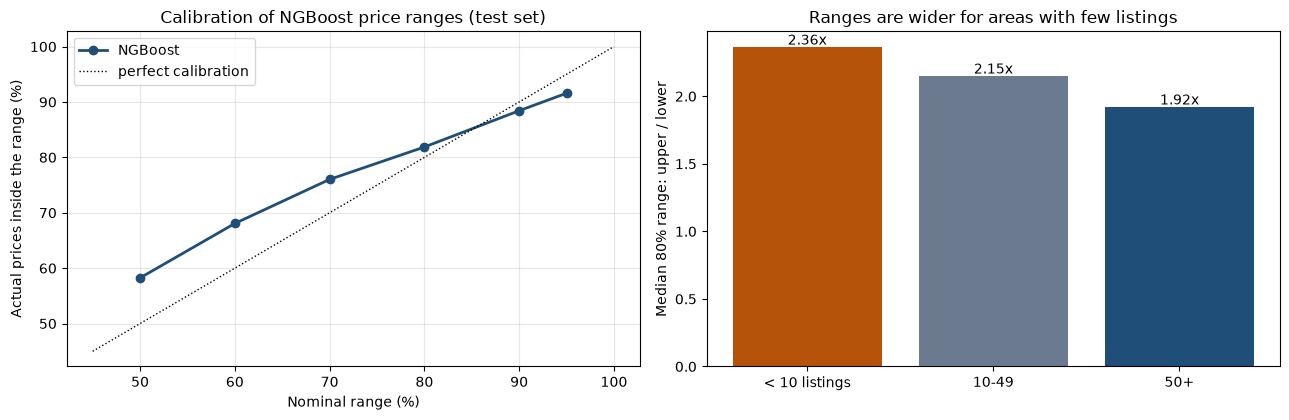

In [6]:
# Are ranges wider where data is thin? Group test listings by how many training listings their area has.
area_counts = X_train["Address"].value_counts()
n_area = X_test["Address"].map(area_counts).fillna(0).values
bins = pd.cut(n_area, [-1, 9, 49, 10_000], labels=["< 10 listings", "10-49", "50+"])
by_rarity = pd.DataFrame({"area size": bins, "range ratio": ratio80, "sigma": sigma}).groupby(
    "area size", observed=True).agg(listings=("sigma", "size"), median_sigma=("sigma", "median"),
                                    median_range_ratio=("range ratio", "median"))
display(by_rarity.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].plot(levels * 100, np.array(coverage) * 100, "o-", color="#1F4E79", lw=2, label="NGBoost")
ax[0].plot([45, 100], [45, 100], "k:", lw=1, label="perfect calibration")
ax[0].set_xlabel("Nominal range (%)"); ax[0].set_ylabel("Actual prices inside the range (%)")
ax[0].set_title("Calibration of NGBoost price ranges (test set)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].bar(by_rarity.index.astype(str), by_rarity["median_range_ratio"], color=["#B45309", "#6B7A8F", "#1F4E79"])
ax[1].set_ylabel("Median 80% range: upper / lower")
ax[1].set_title("Ranges are wider for areas with few listings")
for i, v in enumerate(by_rarity["median_range_ratio"]):
    ax[1].text(i, v + 0.02, f"{v:.2f}x", ha="center")
plt.tight_layout()
plt.savefig("figures/fig13_ngboost_calibration.png", dpi=110, bbox_inches="tight")
plt.show()

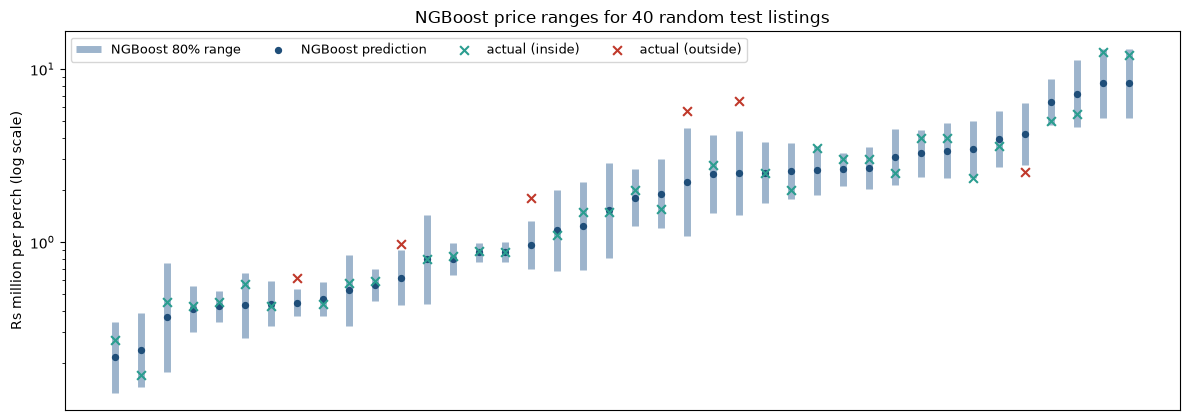

In [7]:
# 40 random test listings: actual price vs NGBoost's 80% range
idx = np.random.default_rng(SEED).choice(len(yt), 40, replace=False)
order = idx[np.argsort(mu[idx])]
fig, ax = plt.subplots(figsize=(12, 4.3))
x = np.arange(len(order))
ax.vlines(x, low80[order] / 1e6, high80[order] / 1e6, color="#9DB4CC", lw=5, label="NGBoost 80% range")
ax.scatter(x, np.expm1(mu[order]) / 1e6, color="#1F4E79", s=18, zorder=3, label="NGBoost prediction")
hit = (np.expm1(yt[order]) >= low80[order]) & (np.expm1(yt[order]) <= high80[order])
ax.scatter(x[hit], np.expm1(yt[order][hit]) / 1e6, color="#2A9D8F", marker="x", s=40, zorder=4, label="actual (inside)")
ax.scatter(x[~hit], np.expm1(yt[order][~hit]) / 1e6, color="#C0392B", marker="x", s=40, zorder=4, label="actual (outside)")
ax.set_yscale("log"); ax.set_ylabel("Rs million per perch (log scale)"); ax.set_xticks([])
ax.set_title("NGBoost price ranges for 40 random test listings"); ax.legend(ncol=4, fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig("figures/fig14_ngboost_ranges.png", dpi=110, bbox_inches="tight")
plt.show()

## 4. What NGBoost learned (SHAP)

SHAP's TreeExplainer supports NGBoost directly. `model_output=0` explains the predicted **mean** (the first
parameter of the Normal distribution). Features are in the model's own order, with the area target-encoded as
a number.

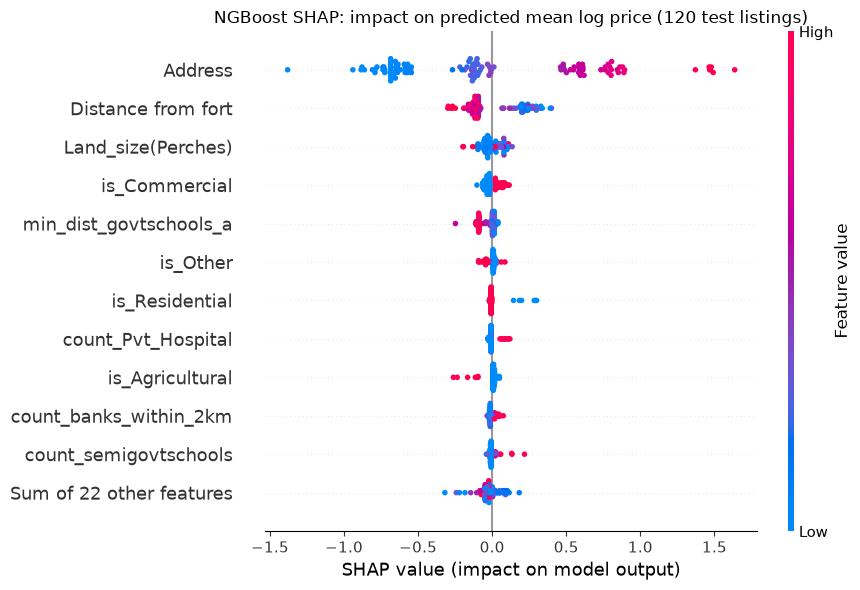

Location (area + 27 distance/count features)    86.1
Land type                                        9.5
Land size                                        4.4
dtype: float64
top features: ['Address', 'Distance from fort', 'Land_size(Perches)', 'is_Commercial', 'min_dist_govtschools_a', 'is_Other']


In [8]:
sample = X_test.sample(120, random_state=SEED)
Xt_sample = best[:-1].transform(sample)
ng_explainer = shap.TreeExplainer(best[-1], model_output=0)
ng_sv = ng_explainer(Xt_sample)
ng_sv.feature_names = FEATURES

shap.plots.beeswarm(ng_sv, max_display=12, show=False)
plt.title("NGBoost SHAP: impact on predicted mean log price (120 test listings)")
plt.gcf().set_size_inches(9, 6)
plt.tight_layout()
plt.savefig("figures/fig15_ngboost_shap.png", dpi=110, bbox_inches="tight")
plt.show()

abs_sv = pd.DataFrame(np.abs(ng_sv.values), columns=FEATURES)
groups = {
    "Location (area + 27 distance/count features)": [c for c in FEATURES if c == "Address" or c.startswith(("min_dist", "count", "Distance"))],
    "Land type": [c for c in FEATURES if c.startswith("is_")],
    "Land size": ["Land_size(Perches)"],
}
share = pd.Series({g: abs_sv[cols].sum(axis=1).mean() for g, cols in groups.items()})
print((share / share.sum() * 100).round(1))
print("top features:", list(abs_sv.mean().sort_values(ascending=False).head(6).index))

## 5. Inference on the held-out listing, and saving the model

In [9]:
x_new = holdout[FEATURES]
d_new = best[-1].pred_dist(best[:-1].transform(x_new))
m_new, s_new = float(d_new.loc[0]), float(d_new.scale[0])
lo, hi = np.expm1(m_new - z80 * s_new), np.expm1(m_new + z80 * s_new)
actual = holdout[TARGET_RAW].iloc[0]
print(f"Dampe, {holdout['Land_size(Perches)'].iloc[0]:g} perches")
print(f"NGBoost prediction: Rs {np.expm1(m_new):,.0f} per perch")
print(f"80% range:          Rs {lo:,.0f} - Rs {hi:,.0f}")
print(f"actual:             Rs {actual:,.0f}  ({'inside' if lo <= actual <= hi else 'outside'} the range)")

ngb_bundle = {
    "model": best,                 # Pipeline: area target-encoding + NGBRegressor (Normal on log1p price)
    "features": FEATURES,
    "z80": float(z80),
    "test_metrics": results["NGBoost (tuned)"],
    "coverage": dict(zip([f"{l:.0%}" for l in levels], map(float, coverage))),
    "nll": float(nll),
}
with open("ngboost_model.pkl", "wb") as f:
    pickle.dump(ngb_bundle, f)
print("saved ngboost_model.pkl")

Dampe, 9.7 perches
NGBoost prediction: Rs 358,370 per perch
80% range:          Rs 274,480 - Rs 467,899
actual:             Rs 300,000  (inside the range)
saved ngboost_model.pkl


## 6. Summary

*Interpreted in the report (Sections 4.3 and 6.7).*